In [96]:
import numpy as np
import pandas as pd

np.random.seed(4)

# Class A cluster
A_x1 = np.random.normal(loc=3, scale=0.3, size=10)
A_x2 = np.random.normal(loc=3, scale=0.3, size=10)

# Class B cluster
B_x1 = np.random.normal(loc=4, scale=0.3, size=10)
B_x2 = np.random.normal(loc=4, scale=0.3, size=10)

df = pd.DataFrame({
    "Feature_1": np.concatenate([A_x1, B_x1]),
    "Feature_2": np.concatenate([A_x2, B_x2]),
    "Target": ["Class_A"] * 10 + ["Class_B"] * 10
})

df.head()

,Feature_1,Feature_2,Target
0,3.015169,3.185601,Class_A
1,3.149985,2.973604,Class_A
2,2.701227,3.127522,Class_A
3,3.208080,3.099676,Class_A
4,2.874510,2.652955,Class_A


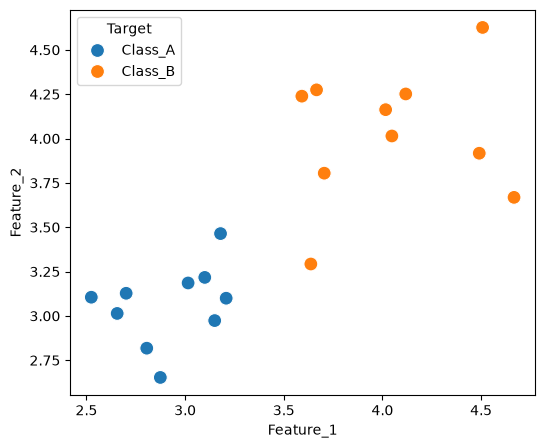

In [97]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df,
    x="Feature_1",
    y="Feature_2",
    s=100,
    hue="Target"
)
plt.show()

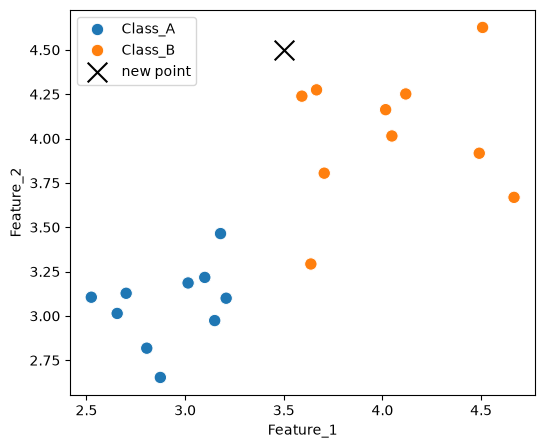

In [98]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df,
    x="Feature_1",
    y="Feature_2",
    hue="Target",
    s=80,
)

plt.scatter(
    x=[3.5],
    y=[4.5],
    c="black",
    s=200,
    marker="x",
    label='new point'
)

plt.legend()

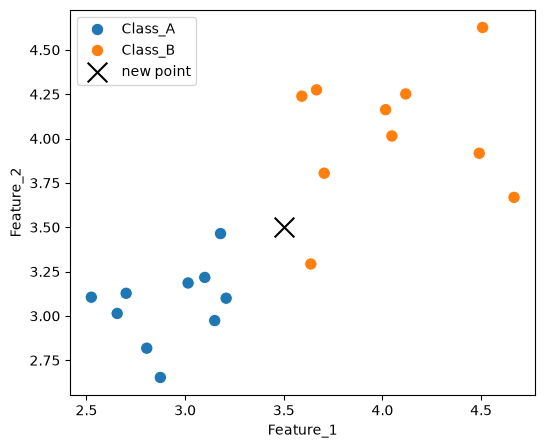

In [99]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df,
    x="Feature_1",
    y="Feature_2",
    hue="Target",
    s=80,
)

plt.scatter(
    x=[3.5],
    y=[3.5],
    c="black",
    s=200,
    marker="x",
    label='new point'
)

plt.legend()

In [100]:
import numpy as np
import pandas as pd

data_point = np.array([3.5, 3.5])

# Euclidean distance for each row
df['Distance'] = np.sqrt(
    (df['Feature_1'] - data_point[0])**2 +
    (df['Feature_2'] - data_point[1])**2
)

df

,Feature_1,Feature_2,Target,Distance
0,3.015169,3.185601,Class_A,0.577848
1,3.149985,2.973604,Class_A,0.632142
2,2.701227,3.127522,Class_A,0.881350
3,3.208080,3.099676,Class_A,0.495456
4,2.874510,2.652955,Class_A,1.052959
5,2.524627,3.105299,Class_A,1.052208
6,2.805688,2.817934,Class_A,0.973285
7,3.179573,3.464094,Class_A,0.322433
8,3.099675,3.217002,Class_A,0.490253
9,2.655757,3.013841,Class_A,0.974216


In [101]:
df.sort_values(by='Distance', inplace=True)
df

,Feature_1,Feature_2,Target,Distance
13,3.637316,3.292578,Class_B,0.248756
7,3.179573,3.464094,Class_A,0.322433
10,3.705103,3.804632,Class_B,0.367244
8,3.099675,3.217002,Class_A,0.490253
3,3.208080,3.099676,Class_A,0.495456
0,3.015169,3.185601,Class_A,0.577848
1,3.149985,2.973604,Class_A,0.632142
19,3.591710,4.238954,Class_B,0.744623
12,4.047968,4.014402,Class_B,0.751584
17,3.666156,4.274452,Class_B,0.792076


In [102]:
import pandas as pd
data = pd.read_csv('./Classified Data.txt', index_col = 0)
data.head()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


In [103]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   WTT           1000 non-null   float64
 1   PTI           1000 non-null   float64
 2   EQW           1000 non-null   float64
 3   SBI           1000 non-null   float64
 4   LQE           1000 non-null   float64
 5   QWG           1000 non-null   float64
 6   FDJ           1000 non-null   float64
 7   PJF           1000 non-null   float64
 8   HQE           1000 non-null   float64
 9   NXJ           1000 non-null   float64
 10  TARGET CLASS  1000 non-null   int64  
dtypes: float64(10), int64(1)
memory usage: 86.1 KB


In [104]:
features = data.drop('TARGET CLASS', axis=1)
target = data['TARGET CLASS']

In [105]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [106]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(scaled_features, target, test_size= 0.8, random_state = 42)

In [107]:
from sklearn.neighbors import KNeighborsClassifier
KNN = KNeighborsClassifier(n_neighbors = 11)
KNN.fit(x_train,y_train)
prediction = KNN.predict(x_test)
from sklearn.metrics import classification_report
print(classification_report(y_test,prediction))


              precision    recall  f1-score   support

           0       0.97      0.90      0.94       401
           1       0.91      0.97      0.94       399

    accuracy                           0.94       800
   macro avg       0.94      0.94      0.94       800
weighted avg       0.94      0.94      0.94       800



In [108]:
from sklearn.metrics import accuracy_score
best_k = None
acc = 0
k = range(1,100,2)

for i in k:
    model= KNeighborsClassifier(n_neighbors = i)
    model.fit(x_train,y_train)
    prediction = model.predict(x_test)

    acc_t= accuracy_score(y_test,prediction)
    if acc_t>acc:
        acc = acc_t
        best_k = i


In [109]:
acc

0.9375